# Instrucciones

 n= último número de su cédula
 Haga todos los cambios que usen n o tengan que ver con esos cambios

**Parte 1:**  

Primero ejecute y analice Taller: Red Neuronal para Prediccion de Demanda de tiquetes aereos; este enseña como implementar redes neuronales en el tipo de problema en cuestion. Primero se hace para tarifa economica. A continuacion, repliquelo para demanda de tariga plena (es muy corto de replicar. IMPORTANTE: Recuerde cambiar el nombre del modelo para no sobreescibir el de la otra variable).


  

**Parte 2 -  Modelo de simulación en Python**
Analice y corra el modelo de simulación descrito en el enunciado, equivalente al desarrollado en Excel. Para la generación de las demandas de tarifa plena y económica, use los modelos de redes neuronales entrenados:
Defina la estación climática y etapa del día para las que va a hacer el análisis.
Por cada iteración de la simulación, genere los valores de entrada necesarios para la predicción ( precios de la competencia) siguiendo las distribuciones ajustadas o las indicadas en el enunciado, y obtenga la demanda como salida del modelo.

Para las demás variables aleatorias del modelo de simulación (precios, costos de indemización, etc), use igualmente las distribuciones ajustadas o indicadas, implementadas con librerías de Python.

  

**Parte 2 - Pseudo-código**
Diseñe el pseudo-código del modelo de simulación del caso. Debe reflejar la lógica completa del modelo, incluyendo la generación de las demandas de tarifa plena y económica mediante predicción con redes neuronales: no el entrenamiento, sino su uso dentro del ciclo de simulación, recibiendo como entrada las variables generadas en cada iteración y retornando la demanda estimada como parte del flujo del modelo.

Para esto puede usar herramientas de construcción de mapas o modelos, hacerlo a mano (subir foto) o en texto plano o enriquecido (.txt o .pdf)

# Taller: Red Neuronal para Prediccion de Demanda de vuelos


## Regresion con MLP en scikit-learn

**Objetivo:** entrenar una red neuronal de regresion para predecir la
**Demanda en Tarifa Economica** a partir de variables de contexto del vuelo y otras empresas.

---

### Contexto

Las **redes neuronales artificiales (RNA)** aprenden patrones en datos
mediante capas de nodos (neuronas) conectados. En **regresion**, la salida
es un valor numérico continuo (la demanda estimada en pasajeros).

El modelo elegido es un **Perceptron Multicapa (MLP)**, apropiado para
regresion tabular con variables mixtas (numericas + categoricas).

Perceptrón: Un perceptrón es el modelo matemático más simple de una neurona artificial y el bloque fundamental de las redes neuronales

El perceptrón multicapa es una red neuronal artificial (RNA) formada por múltiples capas, de tal manera que tiene capacidad para resolver problemas que no son linealmente separables.


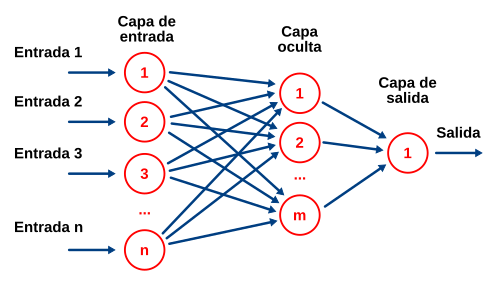

colaboradores de Wikipedia. (2026, 11 enero). Perceptrón multicapa. Wikipedia, la Enciclopedia Libre. https://es.wikipedia.org/wiki/Perceptr%C3%B3n_multicapa#/media/Archivo:Red_neuronal_artificial.svg


**Caracteristicas de entrada:**
- `Estacion Climatica` — categorica (1 a 4)
- `etapa del dia` — categorica (1 a 4)
- `precio competencia tarifa plena` — numerica (USD)
- `precio competencia tarifa economica` — numerica (USD)

**Variable objetivo:** `Demanda Tarifa economica` (entero)

> `Demanda tarifa Plena` existe en el dataset pero se descarta;
> para el taller se entrena con base en la otar

Estacion_climatica            : int   -- 1=Invierno 2=Primavera 3=Verano 4=Otono
etapa_del_dia                 : int   -- 1=Manana 2=Tarde 3=Noche 4=Madrugada
precio_competencia_plena      : float -- precio competencia tarifa plena (USD)
precio_competencia_economica  : float -- precio competencia tarifa economica (USD) de forma analoga en un paso separado.

---
## 1. Librerias
- `pandas` — manejo de datos tabulares
- `numpy` — operaciones numericas
- `scikit-learn` — preprocesamiento, MLP y metricas
- `matplotlib` — visualizacion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

---
## 2. Carga y exploración de datos

Suba el archivo `datos_variables.txt` cuando la celda lo solicite.

In [2]:
from google.colab import files
archivo_subido = files.upload()   # seleccione datos_variables.txt

nombre_archivo = list(archivo_subido.keys())[0]
datos = pd.read_csv(nombre_archivo)

print(f"Filas: {datos.shape[0]} | Columnas: {datos.shape[1]}")
datos.head()

Saving datos_variables.txt to datos_variables.txt
Filas: 627 | Columnas: 6


,Estacion Climatica,etapa del dia,precio competencia tarifa plena,precio competencia tarifa economica,Demanda tarifa Plena,Demanda Tarifa economica
0,4,1,342.81,226.85,99,96
1,3,1,347.12,209.71,93,117
2,2,2,355.25,190.41,63,107
3,3,4,409.41,219.35,68,111
4,1,3,367.59,186.78,53,114


In [3]:
# Revision rapida: tipos, nulos, rangos
print("=== Tipos de dato ===")
print(datos.dtypes)
print("\n=== Valores nulos ===")
print(datos.isnull().sum())
print("\n=== Estadisticas basicas ===")
datos.describe()

=== Tipos de dato ===
Estacion Climatica                       int64
etapa del dia                            int64
precio competencia tarifa plena        float64
precio competencia tarifa economica    float64
Demanda tarifa Plena                     int64
Demanda Tarifa economica                 int64
dtype: object

=== Valores nulos ===
Estacion Climatica                     0
etapa del dia                          0
precio competencia tarifa plena        0
precio competencia tarifa economica    0
Demanda tarifa Plena                   0
Demanda Tarifa economica               0
dtype: int64

=== Estadisticas basicas ===


,Estacion Climatica,etapa del dia,precio competencia tarifa plena,precio competencia tarifa economica,Demanda tarifa Plena,Demanda Tarifa economica
count,627.000000,627.000000,627.000000,627.000000,627.000000,627.000000
mean,2.473684,2.532695,366.640925,205.442584,74.642743,96.925040
std,1.140537,1.101901,30.028547,15.953628,14.730159,13.287162
min,1.000000,1.000000,297.520000,175.340000,50.000000,75.000000
25%,1.000000,2.000000,345.205000,192.050000,62.000000,86.000000
50%,2.000000,3.000000,366.420000,205.180000,74.000000,96.000000
75%,4.000000,4.000000,388.165000,217.600000,87.000000,108.000000
max,4.000000,4.000000,441.440000,239.580000,100.000000,120.000000


In [4]:
# Categorias presentes (deben ser 1, 2, 3, 4)
print("Estacion Climatica:", sorted(datos["Estacion Climatica"].unique()))
print("etapa del dia:      ", sorted(datos["etapa del dia"].unique()))

Estacion Climatica: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
etapa del dia:       [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


# **PRONOSTICO DE DEMANDA EN TARIFA ECONOMICA**



---
## 3. Preprocesamiento

### 3.1 Separar "features" y "target"

Descartamos `Demanda tarifa Plena`; en el otro entrenamiento separado seria el target.

### 3.2 One-Hot Encoding de categoricas

trabajaremos con con numeros. Pasar `Estacion=3` implicaria
que 3 > 2 > 1, lo cual no tiene sentido para una categoria nominal.
Con **One-Hot**, cada categoria pasa a ser una columna binaria (0 o 1):

| Estacion | _1 | _2 | _3 | _4 |
|---|---|---|---|---|
| 3 | 0 | 0 | 1 | 0 |
| 1 | 1 | 0 | 0 | 0 |

### 3.3 Escalado con StandardScaler

Debido a las diferentes dimensiones de de las columnas, esto Transforma cada columna numerica a valores con media 0 y SD 1. Evita que, por ejemplo, precios del orden de 300-400 opaquen columnas binarias (0/1) durante el entrenamiento.

> **Regla clave:** el scaler se ajusta (`fit`) solo con datos de
> entrenamiento y luego se aplica (`transform`) tanto a train como a test,
> para no filtrar informacion del test al modelo.

In [5]:
# Separar features (X) y target (y)
columnas_a_descartar = ["Demanda tarifa Plena", "Demanda Tarifa economica"]    #las descarta como salidas Y
X = datos.drop(columns=columnas_a_descartar)
y = datos["Demanda Tarifa economica"]   #luego debe hacer lo mismo con tarifa plena

print("Features originales:", X.columns.tolist())

Features originales: ['Estacion Climatica', 'etapa del dia', 'precio competencia tarifa plena', 'precio competencia tarifa economica']


In [6]:
# One-Hot Encoding de las variables categoricas (a pesar de que son número figuran como etiquetas 1, 2...)
columnas_categoricas = ["Estacion Climatica", "etapa del dia"]
X_codificado = pd.get_dummies(X, columns=columnas_categoricas, dtype=int)

print("Features despues del encoding:", X_codificado.columns.tolist())
print("Shape:", X_codificado.shape)
X_codificado.head(3)

Features despues del encoding: ['precio competencia tarifa plena', 'precio competencia tarifa economica', 'Estacion Climatica_1', 'Estacion Climatica_2', 'Estacion Climatica_3', 'Estacion Climatica_4', 'etapa del dia_1', 'etapa del dia_2', 'etapa del dia_3', 'etapa del dia_4']
Shape: (627, 10)


,precio competencia tarifa plena,precio competencia tarifa economica,Estacion Climatica_1,Estacion Climatica_2,Estacion Climatica_3,Estacion Climatica_4,etapa del dia_1,etapa del dia_2,etapa del dia_3,etapa del dia_4
0,342.81,226.85,0,0,0,1,1,0,0,0
1,347.12,209.71,0,0,1,0,1,0,0,0
2,355.25,190.41,0,1,0,0,0,1,0,0




```
Nota: La función pd.get_dummies() convierte variables categóricas (texto) en
variables numéricas binarias (0 y 1). Esta técnica es fundamental en Machine
Learning para que los algoritmos puedan procesar datos no numéricos.
  
https://www.geeksforgeeks.org/pandas/python-pandas-get_dummies-method/
```



In [7]:
# Dividir en entrenamiento (80%) y prueba (20%) de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X_codificado, y,
    test_size=0.2,
    random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} filas")
print(f"Prueba:        {X_test.shape[0]} filas")

Entrenamiento: 501 filas
Prueba:        126 filas


In [8]:
# Escalar (fit solo en train para no contaminar el test)
scaler = StandardScaler()
X_train_escalado = scaler.fit_transform(X_train)
X_test_escalado  = scaler.transform(X_test)

# Guardar el orden de columnas; se necesita al predecir casos individuales
columnas_modelo = X_codificado.columns.tolist()
print("Columnas que espera el modelo:", columnas_modelo)

Columnas que espera el modelo: ['precio competencia tarifa plena', 'precio competencia tarifa economica', 'Estacion Climatica_1', 'Estacion Climatica_2', 'Estacion Climatica_3', 'Estacion Climatica_4', 'etapa del dia_1', 'etapa del dia_2', 'etapa del dia_3', 'etapa del dia_4']


---
## 4. Construccion y entrenamiento del modelo

### Arquitectura del MLP

Lo define el modelador (hiperparámetros)
Entrada  (10 features)
    -> Capa oculta 1 : 50 neuronas, ReLU
    -> Capa oculta 2 :  50 neuronas, ReLU
    -> Salida        :   1 valor (demanda predicha)
```

**Parametros clave de MLPRegressor:**
- `hidden_layer_sizes` - tupla con neuronas por capa oculta
- `activation='relu'` - funcion de activacion (la mas usada en regresion)
- `solver='adam'` - optimizador adaptativo, robusto para datasets medianos
- `early_stopping=True` - detiene el entrenamiento si el modelo deja de mejorar
- `max_iter` - maximo de epocas si `early_stopping` no actua antes

In [9]:
modelo_demanda_economica = MLPRegressor(
    hidden_layer_sizes=(50, 50, 5),  #cambie 5 por n
    activation="relu",
    solver="adam",
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,  # 10% del train se usa como validacion interna
    random_state=42
)

modelo_demanda_economica.fit(X_train_escalado, y_train)

print(f"Entrenamiento finalizado en {modelo_demanda_economica.n_iter_} iteraciones.")

Entrenamiento finalizado en 119 iteraciones.


---
## 5. Evaluacion del modelo

- **MAE** (Mean Absolute Error): error promedio en pasajeros.


####

In [10]:
predicciones_test = modelo_demanda_economica.predict(X_test_escalado)

mae = mean_absolute_error(y_test, predicciones_test)

print(f"MAE (Error Absoluto Medio): {mae:.2f} pasajeros")


MAE (Error Absoluto Medio): 12.94 pasajeros


## GRAFICAS

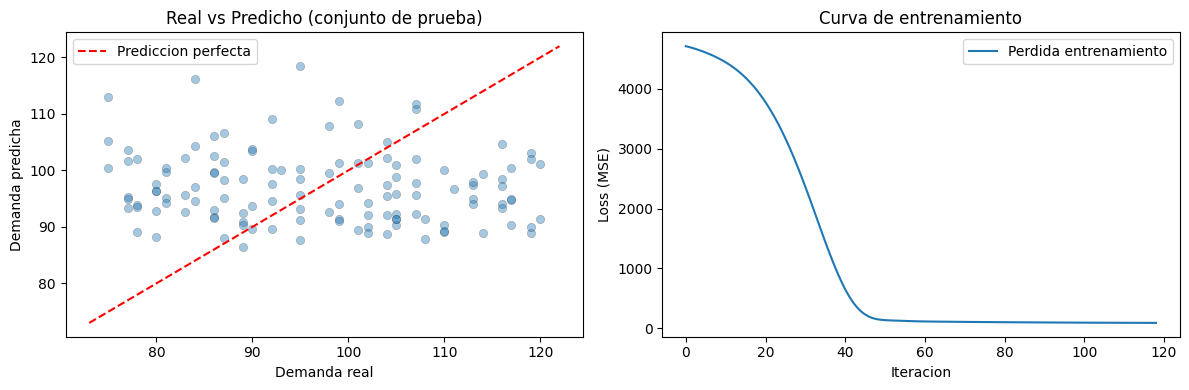

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Dispersión (scatter): real vs predicho ---
axes[0].scatter(y_test, predicciones_test, alpha=0.4, edgecolors='k', linewidths=0.3)
lim = [min(y_test.min(), predicciones_test.min()) - 2,
       max(y_test.max(), predicciones_test.max()) + 2]
axes[0].plot(lim, lim, 'r--', label='Prediccion perfecta')
axes[0].set_xlabel('Demanda real')
axes[0].set_ylabel('Demanda predicha')
axes[0].set_title('Real vs Predicho (conjunto de prueba)')
axes[0].legend()

# --- Curva de perdida ---
axes[1].plot(modelo_demanda_economica.loss_curve_, label='Perdida entrenamiento')
axes[1].set_xlabel('Iteracion')
axes[1].set_ylabel('Loss (MSE)')
axes[1].set_title('Curva de entrenamiento')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 6. Prediccion individual (1 a 1):     Predice la Demanda en Tarifa Economica para un escenario puntual.


Elemento clave para conectar el modelo entrenado con una simulacion:
recibe los valores de un escenario puntual y devuelve la demanda predicha.

> En @Risk, cada iteración genera valores aleatorios de precio de la competencia.
> Esta funcion se llamaria una vez por iteracion, con esos valores,
> para obtener la demanda predicha de ese escenario especifico.

In [13]:
def predecir_demanda_economica(estacion_climatica, etapa_del_dia,
                               precio_competencia_plena,
                               precio_competencia_economica,
                               modelo, scaler, columnas_modelo):
    """

    Parametros
    ----------
    estacion_climatica            : int   -- 1=Invierno 2=Primavera 3=Verano 4=Otono
    etapa_del_dia                 : int   -- 1=Manana 2=Tarde 3=Noche 4=Madrugada
    precio_competencia_plena      : float -- precio competencia tarifa plena (USD)
    precio_competencia_economica  : float -- precio competencia tarifa economica (USD)
    modelo                        : MLPRegressor ya entrenado
    scaler                        : StandardScaler ajustado en entrenamiento
    columnas_modelo               : list  -- orden de columnas que espera el modelo

    Retorna
    -------
    float -- demanda predicha en tarifa economica
    """
    # Construir DataFrame de una sola fila con las features sin codificar
    fila_original = pd.DataFrame({
        "precio competencia tarifa plena":     [precio_competencia_plena],
        "precio competencia tarifa economica": [precio_competencia_economica],
        "Estacion Climatica":                  [estacion_climatica],
        "etapa del dia":                       [etapa_del_dia]
    })

    # Aplicar el mismo One-Hot Encoding del entrenamiento
    fila_codificada = pd.get_dummies(
        fila_original,
        columns=["Estacion Climatica", "etapa del dia"],
        dtype=int
    )

    # reindex garantiza el mismo orden y rellena con 0 las categorias ausentes
    fila_codificada = fila_codificada.reindex(columns=columnas_modelo, fill_value=0)

    # Escalar con el mismo scaler del entrenamiento
    fila_escalada = scaler.transform(fila_codificada)

    demanda_predicha = modelo.predict(fila_escalada)[0] #esta es la linea de predicción <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
    return demanda_predicha

In [14]:
# Ejemplo de predicción de demanda economica a : Verano, vuelo de mañana, precios especificos de la competencia
demanda_estimada = predecir_demanda_economica(
    estacion_climatica=2, #cambielo a 1 para n entre 0 y 2, 2 para n entre 3 y 5; 3 para n entre 6 y 7 y 4 para n entre 8 y 9
    etapa_del_dia=2,    #cambielo a 1 para n entre 0 y 2, 2 para n entre 3 y 5; 3 para n entre 6 y 7 y 4 para n entre 8 y 9
    precio_competencia_plena=380.0,
    precio_competencia_economica=180.0,
    modelo=modelo_demanda_economica,
    scaler=scaler,
    columnas_modelo=columnas_modelo
)

print(f"Demanda Tarifa Economica estimada: {demanda_estimada:.1f} pasajeros")

Demanda Tarifa Economica estimada: 102.3 pasajeros


---
## 7. Multiples escenarios (como en multiples iteraciones en excel con @Risk)

Para mostrar como se conectaria con un simulador, generamos varias
realizaciones aleatorias del precio de la competencia y obtenemos
una prediccion por cada una.

> En el modelo real, estos precios vendrian de distribuciones ajustadas
> (triangular, normal, etc.). Aqui se simulan con `numpy` solo para
> ilustrar el mecanismo de llamada iterativa.

In [15]:
rng = np.random.default_rng(seed=0)   # generador reproducible

# Escenario fijo para todas las iteraciones de esta corrida
estacion_fija    = 2  #cambielo a 1 para n entre 0 y 2, 2 para n entre 3 y 5; 3 para n entre 6 y 7 y 4 para n entre 8 y 9
etapa_fija       = 2  #cambielo a 1 para n entre 0 y 2, 2 para n entre 3 y 5; 3 para n entre 6 y 7 y 4 para n entre 8 y 9
num_simulaciones = 20

# Precios aleatorios (uniformes solo para ilustración y que se mantengan dentro de los rangos, en el taller no usar uniforme!)
precio_competencia_plena     = rng.uniform(300, 440, size=num_simulaciones) #NO usar uniforme en el taller para esto
precio_competencia_economica = rng.uniform(175, 240, size=num_simulaciones)

# Una prediccion por simulacion
demandas_sim = [
    predecir_demanda_economica(
        estacion_fija, etapa_fija,
        precio_p, precio_e,
        modelo_demanda_economica, scaler, columnas_modelo
    )
    for precio_p, precio_e in zip(precio_competencia_plena, precio_competencia_economica)
]

resultados_sim = pd.DataFrame({
    "precio_competencia_plena":     precio_competencia_plena.round(2),
    "precio_competencia_economica": precio_competencia_economica.round(2),
    "demanda_economica_predicha":   [round(d, 1) for d in demandas_sim]
})

print(f"Media demanda predicha: {resultados_sim.demanda_economica_predicha.mean():.1f}")
print(f"SD    demanda predicha: {resultados_sim.demanda_economica_predicha.std():.1f}\n")
resultados_sim

Media demanda predicha: 95.3
SD    demanda predicha: 5.3



,precio_competencia_plena,precio_competencia_economica,demanda_economica_predicha
0,389.17,176.84,103.7
1,337.77,183.08,105.8
2,305.74,218.59,94.2
3,302.31,217.07,95.6
4,413.86,215.00,93.4
5,427.79,199.94,96.0
6,384.93,239.82,91.6
7,402.13,238.75,94.8
8,376.11,219.56,87.7
9,430.91,217.28,97.6


---
## Resumen del flujo

```
-Cargar y limpiar (drop Demanda Plena en este caso)
-One-Hot Encoding  (categoricas -> binarias)
-Train / Test Split  (80 / 20)
-StandardScaler  (fit solo en train)
-MLPRegressor.fit(X_train, y_train)
-Evaluacion  (MAE, R2, graficos)
-predecir_demanda_economica(...)  <-- llamada 1 a 1 por cada simulacion
```

**Para adaptar este taller a otro caso:**
1. Reemplazar el CSV con los datos del nuevo problema.
2. Ajustar `columnas_categoricas` y el nombre del target.
3. Adaptar la funcion de prediccion con los nuevos parametros.


**`MLPRegressor`** - Red neuronal de capas densas conectadas. Aprende representaciones internas mediante backpropagation y funciones de activación no lineales.  

**Ventajas**:

-Muy flexible, puede aprender relaciones complejas y no lineales  
-Escala bien con datasets grandes  
-Ampliamente documentado y enseñado  
-Fácil de ajustar arquitectura (capas, neuronas)  

**Desventajas**:

-Requiere definir arquitectura manualmente  
-Sensible a la escala de los datos (requiere StandardScaler obligatorio)  
-Puede quedarse en mínimos locales  
-Entrenamiento puede ser lento con datos grandes  
-Menos interpretable que los otros dos  
  

# PARA HACER:   Entrenamiento de red neuronal para tarifa plena

Esta seccion replica el entrenamiento que ya se hizo para la tarifa economica, ahora aplicado a la **Demanda en Tarifa Plena** (llamelo modelo_demanda_plena) . El objetivo es contar con un segundo modelo de red neuronal que pueda predecir la demanda de tarifa plena en funcion del precio de la competencia, la estacion climatica y la etapa del dia, de la misma manera en que se hizo para la tarifa economica en las secciones anteriores.

---

# **PRONOSTICO DE DEMANDA EN TARIFA PLENA**



In [ ]:
# Separar features (X) y target (y) para tarifa plena
columnas_a_descartar_plena = ["Demanda Tarifa economica", "Demanda tarifa Plena"]    #las descarta como salidas Y
X_plena = datos.drop(columns=columnas_a_descartar_plena)
y_plena = datos["Demanda tarifa Plena"]

print("Features originales (plena):", X_plena.columns.tolist())

In [ ]:
# One-Hot Encoding de las variables categoricas (igual que en tarifa economica)
X_codificado_plena = pd.get_dummies(X_plena, columns=columnas_categoricas, dtype=int)

print("Features despues del encoding (plena):", X_codificado_plena.columns.tolist())
print("Shape:", X_codificado_plena.shape)
X_codificado_plena.head(3)

In [ ]:
# Dividir en entrenamiento (80%) y prueba (20%) de los datos
X_train_plena, X_test_plena, y_train_plena, y_test_plena = train_test_split(
    X_codificado_plena, y_plena,
    test_size=0.2,
    random_state=42
)

print(f"Entrenamiento: {X_train_plena.shape[0]} filas")
print(f"Prueba:        {X_test_plena.shape[0]} filas")

In [ ]:
# Escalar (fit solo en train para no contaminar el test)
scaler_plena = StandardScaler()
X_train_escalado_plena = scaler_plena.fit_transform(X_train_plena)
X_test_escalado_plena  = scaler_plena.transform(X_test_plena)

# Guardar el orden de columnas; se necesita al predecir casos individuales
columnas_modelo_plena = X_codificado_plena.columns.tolist()
print("Columnas que espera el modelo (plena):", columnas_modelo_plena)

In [ ]:
modelo_demanda_plena = MLPRegressor(
    hidden_layer_sizes=(50, 50, 5),  #cambie 5 por n
    activation="relu",
    solver="adam",
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,  # 10% del train se usa como validacion interna
    random_state=42
)

modelo_demanda_plena.fit(X_train_escalado_plena, y_train_plena)

print(f"Entrenamiento finalizado en {modelo_demanda_plena.n_iter_} iteraciones.")

In [ ]:
predicciones_test_plena = modelo_demanda_plena.predict(X_test_escalado_plena)

mae_plena = mean_absolute_error(y_test_plena, predicciones_test_plena)

print(f"MAE (Error Absoluto Medio) tarifa plena: {mae_plena:.2f} pasajeros")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Dispersión (scatter): real vs predicho ---
axes[0].scatter(y_test_plena, predicciones_test_plena, alpha=0.4, edgecolors='k', linewidths=0.3)
lim = [min(y_test_plena.min(), predicciones_test_plena.min()) - 2,
       max(y_test_plena.max(), predicciones_test_plena.max()) + 2]
axes[0].plot(lim, lim, 'r--', label='Prediccion perfecta')
axes[0].set_xlabel('Demanda real')
axes[0].set_ylabel('Demanda predicha')
axes[0].set_title('Real vs Predicho - tarifa plena (conjunto de prueba)')
axes[0].legend()

# --- Curva de perdida ---
axes[1].plot(modelo_demanda_plena.loss_curve_, label='Perdida entrenamiento')
axes[1].set_xlabel('Iteracion')
axes[1].set_ylabel('Loss (MSE)')
axes[1].set_title('Curva de entrenamiento - tarifa plena')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## Prediccion individual (1 a 1) - Tarifa Plena

Misma logica que `predecir_demanda_economica`, aplicada al modelo entrenado para tarifa plena.

In [ ]:
def predecir_demanda_plena(estacion_climatica, etapa_del_dia,
                           precio_competencia_plena,
                           precio_competencia_economica,
                           modelo, scaler, columnas_modelo):
    """

    Parametros
    ----------
    estacion_climatica            : int   -- 1=Invierno 2=Primavera 3=Verano 4=Otono
    etapa_del_dia                 : int   -- 1=Manana 2=Tarde 3=Noche 4=Madrugada
    precio_competencia_plena      : float -- precio competencia tarifa plena (USD)
    precio_competencia_economica  : float -- precio competencia tarifa economica (USD)
    modelo                        : MLPRegressor ya entrenado
    scaler                        : StandardScaler ajustado en entrenamiento
    columnas_modelo               : list  -- orden de columnas que espera el modelo

    Retorna
    -------
    float -- demanda predicha en tarifa plena
    """
    # Construir DataFrame de una sola fila con las features sin codificar
    fila_original = pd.DataFrame({
        "precio competencia tarifa plena":     [precio_competencia_plena],
        "precio competencia tarifa economica": [precio_competencia_economica],
        "Estacion Climatica":                  [estacion_climatica],
        "etapa del dia":                       [etapa_del_dia]
    })

    # Aplicar el mismo One-Hot Encoding del entrenamiento
    fila_codificada = pd.get_dummies(
        fila_original,
        columns=["Estacion Climatica", "etapa del dia"],
        dtype=int
    )

    # reindex garantiza el mismo orden y rellena con 0 las categorias ausentes
    fila_codificada = fila_codificada.reindex(columns=columnas_modelo, fill_value=0)

    # Escalar con el mismo scaler del entrenamiento
    fila_escalada = scaler.transform(fila_codificada)

    demanda_predicha = modelo.predict(fila_escalada)[0]
    return demanda_predicha

In [ ]:
# Ejemplo de prediccion de demanda plena a : Verano, vuelo de mañana, precios especificos de la competencia
demanda_estimada_plena = predecir_demanda_plena(
    estacion_climatica=2,
    etapa_del_dia=2,
    precio_competencia_plena=380.0,
    precio_competencia_economica=180.0,
    modelo=modelo_demanda_plena,
    scaler=scaler_plena,
    columnas_modelo=columnas_modelo_plena
)

print(f"Demanda Tarifa Plena estimada: {demanda_estimada_plena:.1f} pasajeros")

# SIMULACION DE MONTECARLO

## 2. Parametros fijos del modelo

Se centralizan aqui todos los parametros del modelo para facilitar su modificacion.

### Variable cierta

| Parametro | Valor |
|---|---|
| Capacidad del avion | 112 sillas |

### Escenario fijo del vuelo

Para este ejercicio la estacion climatica y la etapa del dia se fijan en los valores del Excel (`Estacion = 1`, `Etapa = 2`). Corresponden a valores que si se conocen en el momento en que se corre el modelo.

### Variables aleatorias y sus distribuciones

Todas las distribuciones provienen directamente de las formulas @RISK de la hoja **Simulacion dos tarifas** del Excel.

| Variable | Celda Excel | Distribucion @RISK | Implementacion Python |
|---|---|---|---|
| Precio competencia tarifa plena | B4 | `RiskNormal(400, 50)` | `Normal(media=400, desv=50)` |
| Precio competencia tarifa economica | B5 | `RiskNormal(200, 40)` | `Normal(media=200, desv=40)` |
| Porcentaje asistencia tarifa plena | B16 | `RiskNormal(0.70, 0.15, Truncate(0,1))` | `Normal truncada [0,1]` |
| Porcentaje asistencia tarifa economica | B17 | `RiskNormal(0.80, 0.10, Truncate(0,1))` | `Normal truncada [0,1]` |
| Precio tiquete tarifa plena (Piedmont) | B19 | `RiskBetaGeneral(1.6291, 1.1844, 252.17, 498.85)` | `BetaGeneral` |
| Precio tiquete tarifa economica (Piedmont) | B20 | `RiskLogistic(232.296, 31.305)` | `Logistic` |
| Costo compensacion pasajero en tierra plena | B22 | `RiskTriang(494.71, 549, 719.57)` | `Triangular` |
| Costo compensacion pasajero en tierra economica | B23 | `RiskWeibull(1.7313, 137.44, Shift=214.96)` | `Weibull desplazada` |

> La demanda de cada tarifa se predice con las redes neuronales entrenadas, usando como entradas el precio de la competencia y los valores fijos de estacion y etapa del dia.

## 1. Instalacion e importacion de librerias adicionales

In [ ]:
!pip install geneticalgorithm -q

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, truncnorm, beta, logistic, weibull_min
from geneticalgorithm import geneticalgorithm as ga

## 2. Parametros fijos del modelo

Se centralizan aqui todos los parametros deterministicos del problema para facilitar su modificacion.

### Variables ciertas

| Parametro | Valor |
|---|---|
| Capacidad del avion | 112 sillas |

### Variables aleatorias y sus distribuciones

| Variable | Distribucion | Referencia |
|---|---|---|
| Precio tiquete tarifa plena (Piedmont) | Normal(447.78, 30) truncada | Datos historicos Excel |
| Precio tiquete tarifa economica (Piedmont) | Normal(186.29, 20) truncada | Datos historicos Excel |
| Porcentaje de pasajeros de plena que llegan | Normal(0.70, 0.155) truncada [0,1] | Ajuste @RISK |
| Porcentaje de pasajeros de economica que llegan | Normal(0.80, 0.10) truncada [0,1] | Enunciado |
| Precio competencia tarifa plena | Normal(366.641, 30.028) | Ajuste @RISK historicos |
| Precio competencia tarifa economica | BetaGeneral(1.4865, 1.7133, 175.164, 240.294) | Ajuste @RISK historicos |
| Estacion climatica |  {1,2,3,4} |  |Contexto operativo
| Etapa del dia | {1,2,3,4} | Contexto operativo
| Costo compensacion pasajero en tierra plena | Normal(574, 50) truncada | Datos historicos Excel |
| Costo compensacion pasajero en tierra economica | Normal(391, 40) truncada | Datos historicos Excel |

> La demanda de tarifa plena y economica se obtiene de los modelos de red neuronal entrenados en las secciones anteriores, recibiendo como entradas la estacion climatica y la etapa del dia y los precios de la competencia,  generados aleatoriamente en cada iteracion.

---

In [17]:
# Parametros fijos del modelo de sobreventa
CAPACIDAD_AVION = 112
NUMERO_SIMULACIONES = 500  # <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<

# Escenario fijo del vuelo, ejemplo SEGUN EL CONTEXTO DE DECISION
ESTACION_CLIMATICA_VUELO = 2 #invierno  cambielo a
ETAPA_DEL_DIA_VUELO      = 2 #por la tarde

# Precio de la competencia tarifa plena: RiskNormal(400, 50) -- celda B4
PRECIO_COMP_PLENA_MEDIA = 400.0
PRECIO_COMP_PLENA_DESV  = 50.0

# Precio de la competencia tarifa economica: RiskNormal(200, 40) -- celda B5
PRECIO_COMP_ECONOMICA_MEDIA = 200.0
PRECIO_COMP_ECONOMICA_DESV  = 40.0

# Porcentaje de asistencia tarifa plena: RiskNormal(0.70, 0.15, Truncate(0,1)) -- celda B16
ASISTENCIA_PLENA_MEDIA = 0.70
ASISTENCIA_PLENA_DESV  = 0.15

# Porcentaje de asistencia tarifa economica: RiskNormal(0.80, 0.10, Truncate(0,1)) -- celda B17
ASISTENCIA_ECONOMICA_MEDIA = 0.80
ASISTENCIA_ECONOMICA_DESV  = 0.10

# Precio tiquete tarifa plena (Piedmont): RiskBetaGeneral(1.6291, 1.1844, 252.17, 498.85) -- celda B19
PRECIO_TIQUETE_PLENA_ALPHA1 = 1.6291
PRECIO_TIQUETE_PLENA_ALPHA2 = 1.1844
PRECIO_TIQUETE_PLENA_MIN    = 252.17
PRECIO_TIQUETE_PLENA_MAX    = 498.85

# Precio tiquete tarifa economica (Piedmont): RiskLogistic(232.296, 31.305) -- celda B20
PRECIO_TIQUETE_ECONOMICA_LOC   = 232.296
PRECIO_TIQUETE_ECONOMICA_SCALE = 31.305

# Costo compensacion pasajero en tierra plena: RiskTriang(494.71, 549, 719.57) -- celda B22
COSTO_COMP_PLENA_MIN  = 494.71
COSTO_COMP_PLENA_MODA = 549.0
COSTO_COMP_PLENA_MAX  = 719.57

# Costo compensacion pasajero en tierra economica:
# RiskWeibull(1.7313, 137.44, Shift(214.96)) -- celda B23
COSTO_COMP_ECONOMICA_FORMA        = 1.7313
COSTO_COMP_ECONOMICA_ESCALA       = 137.44
COSTO_COMP_ECONOMICA_DESPLAZAMIENTO = 214.96

# Multa al pasajero de economica que no llega: 50% del precio del tiquete
FRACCION_MULTA_ECONOMICA = 0.50

print("Parametros cargados correctamente.")

Parametros cargados correctamente.


## 3. Simulacion Monte Carlo vectorizada

En lugar de un bucle Python que llama a `simular_escenario_vuelo` una iteracion a la vez, la simulacion se vectoriza: todas las variables aleatorias de las `N` iteraciones se generan de una sola vez como arrays de numpy, y la prediccion de demanda se hace con una unica llamada a `predict()` sobre un batch de `N` filas.

Esto elimina el overhead de Python por iteracion y aprovecha las operaciones matriciales de numpy y scikit-learn, logrando una aceleracion de 10 a 20 veces respecto al bucle escalar.

### Flujo vectorizado

```
1. Fijar estacion = 1 y etapa del dia = 2 para las N iteraciones
2. Generar N precios de competencia de una vez (Normal)
3. Construir batch de N filas y predecir demanda con una sola llamada a predict()
4. Generar el resto de variables aleatorias como arrays de N elementos
5. Calcular la logica del modelo con operaciones numpy sobre arrays
6. Retornar la media de las N utilidades netas
```

> Los pasajeros de tarifa plena tienen prioridad para abordar. Solo se indemnizan los que llegaron y no tuvieron silla disponible.

In [20]:
# Referencias seguras a los objetos del entrenamiento economico
scaler_economica          = scaler
columnas_modelo_economica = columnas_modelo


def predecir_demanda_economica_vuelo(estacion_climatica, etapa_del_dia,
                                     precio_competencia_plena,
                                     precio_competencia_economica):
    """
    Predice la Demanda en Tarifa Economica para un escenario puntual (1 fila).
    Usada en la verificacion individual; la simulacion usa la version en batch.
    """
    fila = pd.DataFrame({
        "precio competencia tarifa plena":     [precio_competencia_plena],
        "precio competencia tarifa economica": [precio_competencia_economica],
        "Estacion Climatica":                  [estacion_climatica],
        "etapa del dia":                       [etapa_del_dia]
    })
    fila = pd.get_dummies(fila, columns=["Estacion Climatica", "etapa del dia"], dtype=int)
    fila = fila.reindex(columns=columnas_modelo_economica, fill_value=0)
    return max(0.0, float(modelo_demanda_economica.predict(scaler_economica.transform(fila))[0]))


def predecir_demanda_plena_vuelo(estacion_climatica, etapa_del_dia,
                                 precio_competencia_plena,
                                 precio_competencia_economica):
    """
    Predice la Demanda en Tarifa Plena para un escenario puntual (1 fila).
    Usada en la verificacion individual; la simulacion usa la version en batch.
    """
    fila = pd.DataFrame({
        "precio competencia tarifa plena":     [precio_competencia_plena],
        "precio competencia tarifa economica": [precio_competencia_economica],
        "Estacion Climatica":                  [estacion_climatica],
        "etapa del dia":                       [etapa_del_dia]
    })
    fila = pd.get_dummies(fila, columns=["Estacion Climatica", "etapa del dia"], dtype=int)
    fila = fila.reindex(columns=columnas_modelo_plena, fill_value=0)
    return max(0.0, float(modelo_demanda_plena.predict(scaler_plena.transform(fila))[0]))


def predecir_demanda_batch(precios_comp_plena, precios_comp_economica,
                           estacion, etapa):
    """
    Predice demanda de tarifa plena y economica para N escenarios simultaneos.

    Parametros
    ----------
    precios_comp_plena      : array(N) -- precios competencia tarifa plena
    precios_comp_economica  : array(N) -- precios competencia tarifa economica
    estacion                : int      -- estacion climatica fija
    etapa                   : int      -- etapa del dia fija

    Retorna
    -------
    demandas_plena, demandas_economica : arrays(N)
    """
    N = len(precios_comp_plena)

    batch = pd.DataFrame({
        "precio competencia tarifa plena":     precios_comp_plena,
        "precio competencia tarifa economica": precios_comp_economica,
        "Estacion Climatica":                  np.full(N, estacion),
        "etapa del dia":                       np.full(N, etapa)
    })

    batch_cod = pd.get_dummies(batch, columns=["Estacion Climatica", "etapa del dia"], dtype=int)

    batch_eco = batch_cod.reindex(columns=columnas_modelo_economica, fill_value=0)
    demandas_economica = np.maximum(
        0.0, modelo_demanda_economica.predict(scaler_economica.transform(batch_eco))
    )

    batch_pln = batch_cod.reindex(columns=columnas_modelo_plena, fill_value=0)
    demandas_plena = np.maximum(
        0.0, modelo_demanda_plena.predict(scaler_plena.transform(batch_pln))
    )


    return demandas_plena, demandas_economica


# Verificacion individual
prueba_eco = predecir_demanda_economica_vuelo(1, 2, 400.0, 200.0)
prueba_pln = predecir_demanda_plena_vuelo(1, 2, 400.0, 200.0)

# Verificacion batch
dp, de = predecir_demanda_batch(
    np.array([400.0, 380.0, 420.0]),
    np.array([200.0, 190.0, 210.0]),
    estacion=1, etapa=2
)

print(f"Verificacion individual -> economica: {prueba_eco:.1f} | plena: {prueba_pln:.1f}")
print(f"Verificacion batch -> economica:{de.round(1)} | plena:{dp.round(1)}")

NameError: name 'columnas_modelo_plena' is not defined

## 4. Funcion objetivo para el algoritmo genetico

La libreria de **Algoritmo Genetico (GA)** minimiza por defecto. Como se quiere **maximizar** la utilidad neta esperada, se retorna el negativo de la media.

El vector de decision `x` tiene dos componentes:
```
x[0] -> total de sillas ofrecidas  (rango: [112, 160])
x[1] -> porcentaje tarifa plena    (rango: [0.20, 1.0])
```

Por cada candidato que evalua el GA se corren `NUMERO_SIMULACIONES` escenarios Monte Carlo y se calcula la media de la utilidad neta.

In [ ]:
def simular_n_escenarios_vuelo(total_sillas_ofrecidas, porcentaje_tarifa_plena, n):   #esto para cada individuo del GA
    """
    Simula N iteraciones del modelo de sobreventa del vuelo 343 de forma vectorizada.
    Genera todas las variables aleatorias como arrays y hace una sola llamada
    a predict() por tarifa, en lugar de N llamadas individuales.

    Parametros
    ----------
    total_sillas_ofrecidas  : float -- total de sillas puestas a la venta
    porcentaje_tarifa_plena : float -- fraccion [0, 1] de sillas para tarifa plena
    n                       : int   -- numero de iteraciones a simular

    Retorna
    -------
    array(n) -- utilidades netas de cada escenario simulado
    """

    # --- Precio de la competencia: Normal (celdas B4 y B5 en excel) ---
    precios_comp_plena = np.random.normal(PRECIO_COMP_PLENA_MEDIA,    PRECIO_COMP_PLENA_DESV,    n)
    precios_comp_eco   = np.random.normal(PRECIO_COMP_ECONOMICA_MEDIA, PRECIO_COMP_ECONOMICA_DESV, n)

    # --- Demanda predicha por redes neuronales (una sola llamada para N filas) ---
    demandas_plena, demandas_eco = predecir_demanda_batch(
        precios_comp_plena, precios_comp_eco,
        estacion=ESTACION_CLIMATICA_VUELO,
        etapa=ETAPA_DEL_DIA_VUELO
    )

    # --- Precio tiquete plena: BetaGeneral(1.6291, 1.1844, 252.17, 498.85) celda B19 ---
    rango_plena = PRECIO_TIQUETE_PLENA_MAX - PRECIO_TIQUETE_PLENA_MIN
    precios_tiq_plena = (
        PRECIO_TIQUETE_PLENA_MIN
        + rango_plena * beta.rvs(PRECIO_TIQUETE_PLENA_ALPHA1, PRECIO_TIQUETE_PLENA_ALPHA2, size=n)
    )

    # --- Precio tiquete economica: Logistic(232.296, 31.305) celda B20 ---
    precios_tiq_eco = logistic.rvs(
        loc=PRECIO_TIQUETE_ECONOMICA_LOC, scale=PRECIO_TIQUETE_ECONOMICA_SCALE, size=n
    )

    # --- Porcentaje de asistencia: Normal truncada en [0, 1] (celdas B16 y B17) ---
    fracciones_asist_plena = truncnorm.rvs(
        a=(0.0 - ASISTENCIA_PLENA_MEDIA) / ASISTENCIA_PLENA_DESV,
        b=(1.0 - ASISTENCIA_PLENA_MEDIA) / ASISTENCIA_PLENA_DESV,
        loc=ASISTENCIA_PLENA_MEDIA, scale=ASISTENCIA_PLENA_DESV, size=n
    )
    fracciones_asist_eco = truncnorm.rvs(
        a=(0.0 - ASISTENCIA_ECONOMICA_MEDIA) / ASISTENCIA_ECONOMICA_DESV,
        b=(1.0 - ASISTENCIA_ECONOMICA_MEDIA) / ASISTENCIA_ECONOMICA_DESV,
        loc=ASISTENCIA_ECONOMICA_MEDIA, scale=ASISTENCIA_ECONOMICA_DESV, size=n
    )

    # --- Costo compensacion plena: Triangular(494.71, 549, 719.57) celda B22 ---
    costos_comp_plena = np.random.triangular(
        COSTO_COMP_PLENA_MIN, COSTO_COMP_PLENA_MODA, COSTO_COMP_PLENA_MAX, size=n
    )

    # --- Costo compensacion economica: Weibull(1.7313, 137.44, Shift=214.96) celda B23 ---
    costos_comp_eco = (
        COSTO_COMP_ECONOMICA_DESPLAZAMIENTO
        + weibull_min.rvs(COSTO_COMP_ECONOMICA_FORMA, scale=COSTO_COMP_ECONOMICA_ESCALA, size=n)
    )

    # --- Logica del modelo de sobreventa (operaciones vectoriales) ---

    sillas_pot_plena = int(round(total_sillas_ofrecidas * porcentaje_tarifa_plena))
    sillas_pot_eco   = int(total_sillas_ofrecidas) - sillas_pot_plena

    ventas_plena = np.minimum(demandas_plena, sillas_pot_plena)
    ventas_eco   = np.minimum(demandas_eco,   sillas_pot_eco)

    llegados_plena = np.round(ventas_plena * fracciones_asist_plena).astype(int)
    llegados_eco   = np.round(ventas_eco   * fracciones_asist_eco).astype(int)

    viajan_plena        = np.minimum(llegados_plena, CAPACIDAD_AVION)
    sillas_disp_eco     = CAPACIDAD_AVION - viajan_plena
    viajan_eco          = np.minimum(llegados_eco, sillas_disp_eco)

    en_tierra_plena = np.maximum(0, llegados_plena - viajan_plena)
    en_tierra_eco   = np.maximum(0, llegados_eco   - viajan_eco)

    no_llegaron_eco = np.maximum(0, ventas_eco.astype(int) - llegados_eco)

    ingresos_plena           = viajan_plena * precios_tiq_plena
    ingresos_eco             = viajan_eco   * precios_tiq_eco
    ingresos_multa_eco       = no_llegaron_eco * precios_tiq_eco * FRACCION_MULTA_ECONOMICA

    costo_total_compensacion = (
        en_tierra_plena * costos_comp_plena
        + en_tierra_eco * costos_comp_eco
    )

    utilidades = ingresos_plena + ingresos_eco + ingresos_multa_eco - costo_total_compensacion
    return utilidades


# Verificacion: media de 500 iteraciones de prueba
utilidades_prueba = simular_n_escenarios_vuelo(
    total_sillas_ofrecidas=136,
    porcentaje_tarifa_plena=0.49,
    n=500
)
print(f"Utilidad neta media (500 iteraciones de prueba): ${utilidades_prueba.mean():,.2f}")
print(f"Desviacion estandar:                             ${utilidades_prueba.std():,.2f}")

Utilidad neta media (500 iteraciones de prueba): $32,096.33
Desviacion estandar:                             $5,440.83


## 5. Configuracion del algoritmo genetico

Se usan los mismos parametros del taller SHECO, adaptados al espacio de decision de este problema.

| Parametro | Valor | Descripcion |
|---|---|---|
| `max_num_iteration` | 300 | Maximo de generaciones |
| `population_size` | 50 | Soluciones candidatas por generacion |
| `mutation_probability` | 0.1 | Probabilidad de mutacion |
| `max_iteration_without_improv` | 75 | Criterio de parada por estancamiento |

> Para resultados finales se recomienda `max_num_iteration = 1000` y `max_iteration_without_improv = 200`.

In [ ]:
def funcion_objetivo_utilidad(x):
    """
    Funcion objetivo para el algoritmo genetico.
    Retorna el negativo de la utilidad neta media estimada con simulacion
    Monte Carlo vectorizada (una sola llamada para todas las iteraciones).

    Parametros
    ----------
    x : array [total_sillas_ofrecidas, porcentaje_tarifa_plena]

    Retorna
    -------
    float -- negativo de la utilidad neta media estimada
    """
    utilidades = simular_n_escenarios_vuelo(
        total_sillas_ofrecidas  = x[0],
        porcentaje_tarifa_plena = x[1],
        n = NUMERO_SIMULACIONES
    )
    return -np.mean(utilidades)

## 6. Ejecucion de la optimizacion

El GA busca la combinacion de sillas ofrecidas y porcentaje en tarifa plena que maximiza la utilidad neta esperada del vuelo.

Iniciando optimizacion con algoritmo genetico...
  Simulaciones por evaluacion: 500
  Iteraciones maximas: 500

 The best solution found:
 [168.67249186   0.59334076]

 Objective function:
 -34447.78449735245


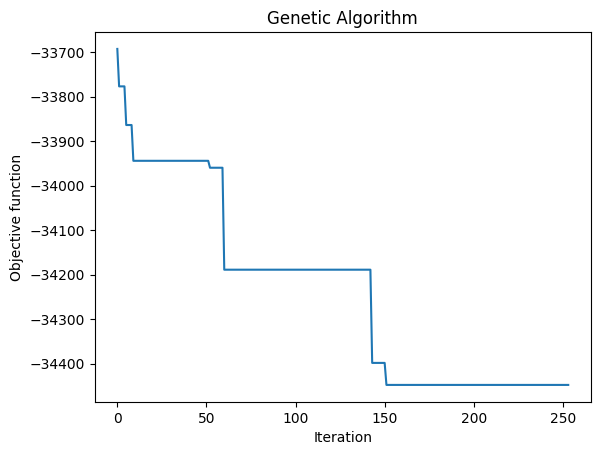


=== RESULTADO DE LA OPTIMIZACION ===
  Sillas optimas a ofrecer:          169
  Porcentaje optimo tarifa plena:    59.33%
  Porcentaje optimo tarifa economica:40.67%
  Sillas estimadas tarifa plena:     100
  Sillas estimadas tarifa economica: 69
  Utilidad neta media estimada:      $34,447.78


In [ ]:
# Limites de las variables de decision
limites_variables = np.array([
    [112, 200],   # total de sillas ofrecidas
    [0.20, 1.0]   # porcentaje de sillas en tarifa plena (minimo 20%)
])

parametros_algoritmo = {
    "max_num_iteration":            500,  # <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
    "population_size":              50,  # <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
    "mutation_probability":         0.1,
    "elit_ratio":                   0.01,
    "crossover_probability":        0.5,
    "parents_portion":              0.3,
    "crossover_type":               "uniform",
    "max_iteration_without_improv": 100  # <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<
}

#CAMBIE LOS PARAMETROS DE GA A VALORES CERCANO A LOS QUE SE PRESENTAN

print("Iniciando optimizacion con algoritmo genetico...")
print(f"  Simulaciones por evaluacion: {NUMERO_SIMULACIONES}")
print(f"  Iteraciones maximas: {parametros_algoritmo['max_num_iteration']}")
print()

modelo_optimizacion = ga(
    function=funcion_objetivo_utilidad,
    dimension=2,
    variable_type='real',
    variable_boundaries=limites_variables,
    algorithm_parameters=parametros_algoritmo
)
modelo_optimizacion.run()

# Extraer la solucion optima
solucion_optima          = modelo_optimizacion.output_dict["variable"]
sillas_optimas           = solucion_optima[0]
porcentaje_plena_optimo  = solucion_optima[1]
porcentaje_economica_optimo = 1.0 - porcentaje_plena_optimo
utilidad_maxima_estimada = -modelo_optimizacion.best_function

print()
print("=== RESULTADO DE LA OPTIMIZACION ===")
print(f"  Sillas optimas a ofrecer:          {sillas_optimas:.0f}")
print(f"  Porcentaje optimo tarifa plena:    {porcentaje_plena_optimo:.2%}")
print(f"  Porcentaje optimo tarifa economica:{porcentaje_economica_optimo:.2%}")
print(f"  Sillas estimadas tarifa plena:     {round(sillas_optimas * porcentaje_plena_optimo):.0f}")
print(f"  Sillas estimadas tarifa economica: {round(sillas_optimas * porcentaje_economica_optimo):.0f}")
print(f"  Utilidad neta media estimada:      ${utilidad_maxima_estimada:,.2f}")

## 7. Evaluacion final con la solucion optima

Con los valores optimos fijos, se corre una simulacion Monte Carlo independiente de mayor tamano para caracterizar la distribucion completa de la utilidad neta. Este paso replica lo que hace Excel con @RISK: copiar la solucion optima y simular para obtener estadisticos.

In [ ]:
SIMULACIONES_EVALUACION_FINAL = 500  # <<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<

utilidades_finales = simular_n_escenarios_vuelo(
    total_sillas_ofrecidas  = sillas_optimas,
    porcentaje_tarifa_plena = porcentaje_plena_optimo,
    n = SIMULACIONES_EVALUACION_FINAL
)

print("=== ESTADISTICOS DE LA SOLUCION OPTIMA ===")
print(f"  Sillas a ofrecer:                {sillas_optimas:.0f}")
print(f"  Porcentaje tarifa plena:         {porcentaje_plena_optimo:.2%}")
print(f"  Sillas tarifa plena:             {round(sillas_optimas * porcentaje_plena_optimo):.0f}")
print(f"  Sillas tarifa economica:         {round(sillas_optimas * porcentaje_economica_optimo):.0f}")
print(f"  Utilidad neta media:             ${np.mean(utilidades_finales):>12,.2f}")
print(f"  Desviacion estandar:             ${np.std(utilidades_finales):>12,.2f}")
print(f"  Percentil  5%:                   ${np.percentile(utilidades_finales,  5):>12,.2f}")
print(f"  Percentil 95%:                   ${np.percentile(utilidades_finales, 95):>12,.2f}")
print(f"  Maximo observado:                ${np.max(utilidades_finales):>12,.2f}")
print(f"  Minimo observado:                ${np.min(utilidades_finales):>12,.2f}")

=== ESTADISTICOS DE LA SOLUCION OPTIMA ===
  Sillas a ofrecer:                169
  Porcentaje tarifa plena:         59.33%
  Sillas tarifa plena:             100
  Sillas tarifa economica:         69
  Utilidad neta media:             $   33,704.51
  Desviacion estandar:             $    5,726.80
  Percentil  5%:                   $   24,112.15
  Percentil 95%:                   $   42,682.15
  Maximo observado:                $   51,859.35
  Minimo observado:                $   16,325.37


## 8. Graficos de resultados

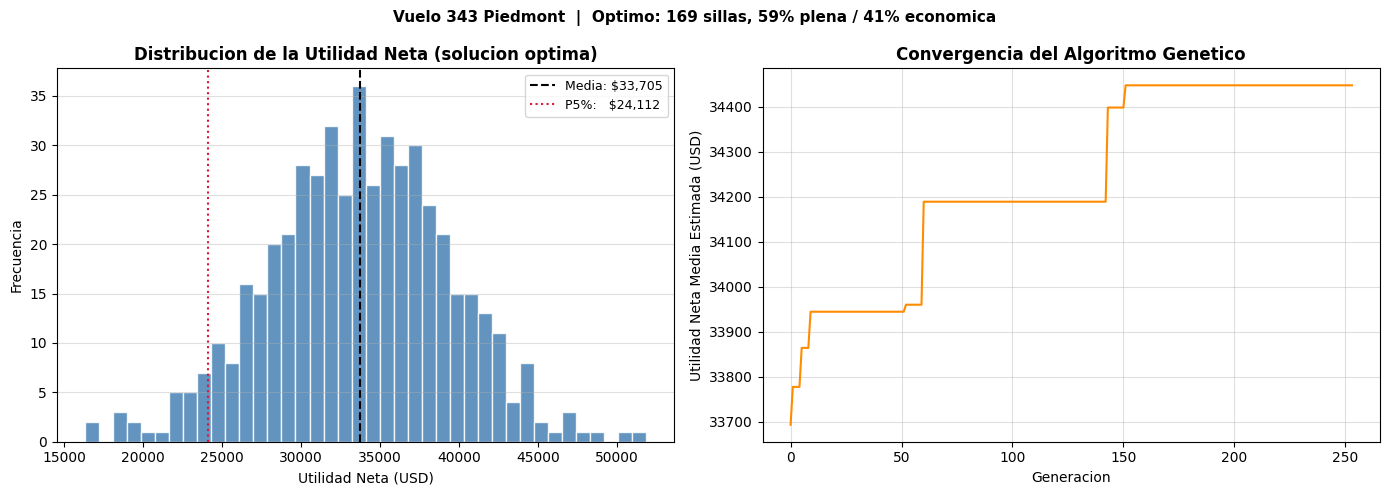

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(utilidades_finales, bins=40, color='steelblue',
             edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(utilidades_finales), color='black', ls='--', lw=1.5,
               label=f"Media: ${np.mean(utilidades_finales):,.0f}")
axes[0].axvline(np.percentile(utilidades_finales, 5), color='crimson', ls=':', lw=1.5,
               label=f"P5%:   ${np.percentile(utilidades_finales, 5):,.0f}")
axes[0].set_title('Distribucion de la Utilidad Neta (solucion optima)', fontweight='bold')
axes[0].set_xlabel('Utilidad Neta (USD)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.4)

convergencia = modelo_optimizacion.report
axes[1].plot([-v for v in convergencia], color='darkorange', lw=1.5)
axes[1].set_title('Convergencia del Algoritmo Genetico', fontweight='bold')
axes[1].set_xlabel('Generacion')
axes[1].set_ylabel('Utilidad Neta Media Estimada (USD)')
axes[1].grid(alpha=0.4)

plt.suptitle(
    f'Vuelo 343 Piedmont  |  Optimo: {sillas_optimas:.0f} sillas, '
    f'{porcentaje_plena_optimo:.0%} plena / {porcentaje_economica_optimo:.0%} economica',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.show()

## 9. Analisis de sensibilidad: comparacion de escenarios

Para contextualizar el resultado optimo, se evaluan tres politicas:
- **Sin sobreventa**: 112 sillas, 49% plena (configuracion base del Excel)
- **Sobreventa moderada**: 130 sillas, 49% plena
- **Solucion optima** encontrada por el GA

In [ ]:
escenarios = [
    (112,  0.49,  "Sin sobreventa (base)"),
    (130,  0.49,  "Sobreventa moderada"),
    (sillas_optimas, porcentaje_plena_optimo, "Solucion optima (GA)")
]

resultados_escenarios = []
for total_sillas, pct_plena, etiqueta in escenarios:
    utilidades = simular_n_escenarios_vuelo(
        total_sillas_ofrecidas  = total_sillas,
        porcentaje_tarifa_plena = pct_plena,
        n = SIMULACIONES_EVALUACION_FINAL
    )
    resultados_escenarios.append({
        "etiqueta":       etiqueta,
        "sillas":         total_sillas,
        "pct_plena":      pct_plena,
        "utilidad_media": np.mean(utilidades),
        "desv_estandar":  np.std(utilidades),
        "percentil_5":    np.percentile(utilidades, 5),
        "utilidades":     utilidades
    })

SEP = '=' * 90
print('\n' + SEP)
print(f"{'ESCENARIO':<35} {'Sillas':>7} {'% Plena':>9} {'Media':>13} {'Desv.Est.':>12} {'P5%':>12}")
print(SEP)
for r in resultados_escenarios:
    print(
        f"{r['etiqueta']:<35} "
        f"{r['sillas']:>7.0f} "
        f"{r['pct_plena']:>9.1%} "
        f"${r['utilidad_media']:>12,.0f} "
        f"${r['desv_estandar']:>11,.0f} "
        f"${r['percentil_5']:>11,.0f}"
    )
print(SEP)


ESCENARIO                            Sillas   % Plena         Media    Desv.Est.          P5%
Sin sobreventa (base)                   112     49.0% $      27,421 $      4,988 $     19,674
Sobreventa moderada                     130     49.0% $      30,973 $      5,512 $     22,376
Solucion optima (GA)                    169     59.3% $      33,450 $      5,480 $     24,981


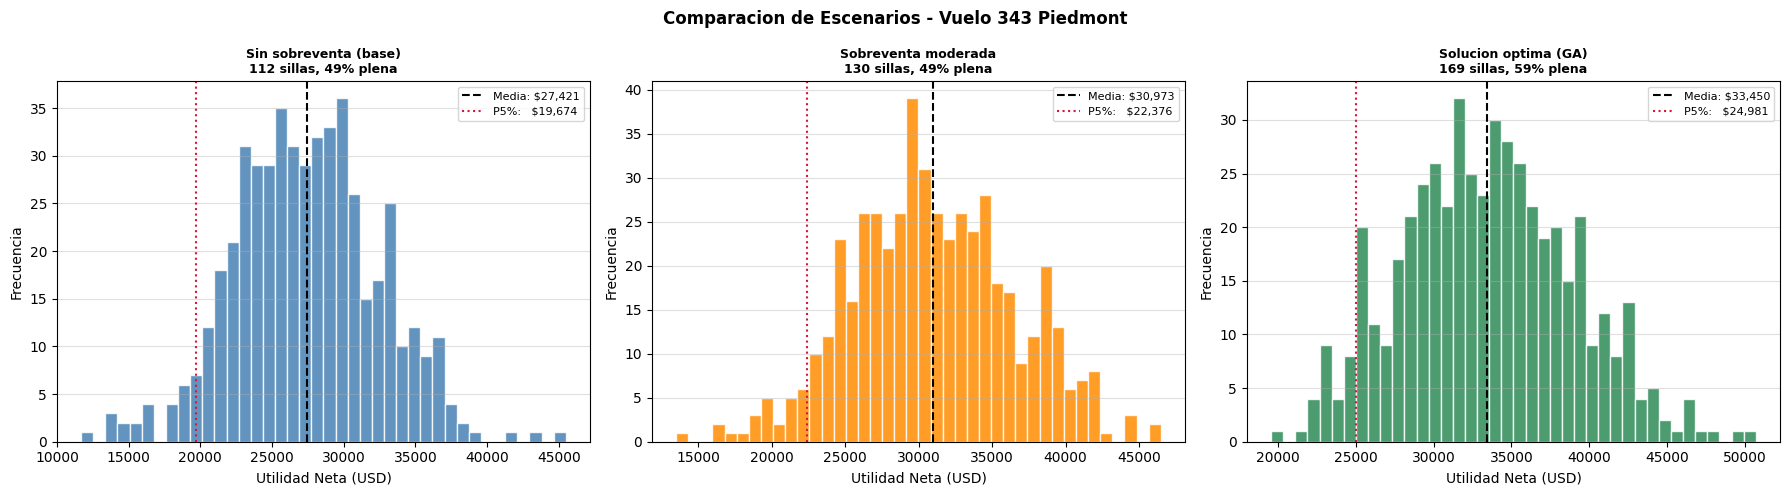

In [ ]:
colores_escenarios = ['steelblue', 'darkorange', 'seagreen']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, resultado, color in zip(axes, resultados_escenarios, colores_escenarios):
    ax.hist(resultado['utilidades'], bins=40, color=color,
            edgecolor='white', alpha=0.85)
    ax.axvline(resultado['utilidad_media'], color='black', ls='--', lw=1.5,
              label=f"Media: ${resultado['utilidad_media']:,.0f}")
    ax.axvline(resultado['percentil_5'], color='crimson', ls=':', lw=1.5,
              label=f"P5%:   ${resultado['percentil_5']:,.0f}")
    ax.set_title(
        f"{resultado['etiqueta']}\n"
        f"{resultado['sillas']:.0f} sillas, {resultado['pct_plena']:.0%} plena",
        fontsize=9, fontweight='bold'
    )
    ax.set_xlabel('Utilidad Neta (USD)')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.4)

plt.suptitle(
    'Comparacion de Escenarios - Vuelo 343 Piedmont',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()